# Lecture 4 — Scatter & Bubble Charts: Gapminder

**GitHub path:** `week04/lecture04_exercise.ipynb`

Dataset: Gapminder, loaded with `plotly.express` (`px.data.gapminder()`). The dataset contains 1,704 country-year rows, including GDP per capita, life expectancy, population, continent, and year.

Design choices: GDP per capita uses a log scale; colour is restrained; only a few notable countries are labelled; bubble sizes are capped. Both chart previews are embedded so they display on GitHub.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

df = px.data.gapminder()
print(f"Loaded: {len(df):,} rows")
print(df.head())


Loaded: 1,704 rows\n       country continent  year  lifeExp       pop   gdpPercap iso_alpha  iso_num
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG        4
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG        4
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG        4
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG        4
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG        4\n

## Explore the dataset

In [2]:
df.info()
print("Years:", sorted(df["year"].unique()))
print("Continents:", sorted(df["continent"].unique()))
print(df.describe().round(1))


Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]\nContinents: ['Africa', 'Americas', 'Asia', 'Europe', 'Oceania']\n         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    425.9
std      17.3     12.9  1.061579e+08     9857.5    248.3
min    1952.0     23.6  6.001100e+04      241.2      4.0
25%    1965.8     48.2  2.793664e+06     1202.1    208.0
50%    1979.5     60.7  7.023596e+06     3531.8    410.0
75%    1993.2     70.8  1.958522e+07     9325.5    638.0
max    2007.0     82.6  1.318683e+09   113523.1    894.0\n

## Task 1 — Scatter: life expectancy change over time

**Insight:** Across Asia, life expectancy generally rose from 2002 to 2007 while GDP per capita changed at different rates. The two colours distinguish years, and arrows show each country's direction of movement. Africa is excluded as instructed.

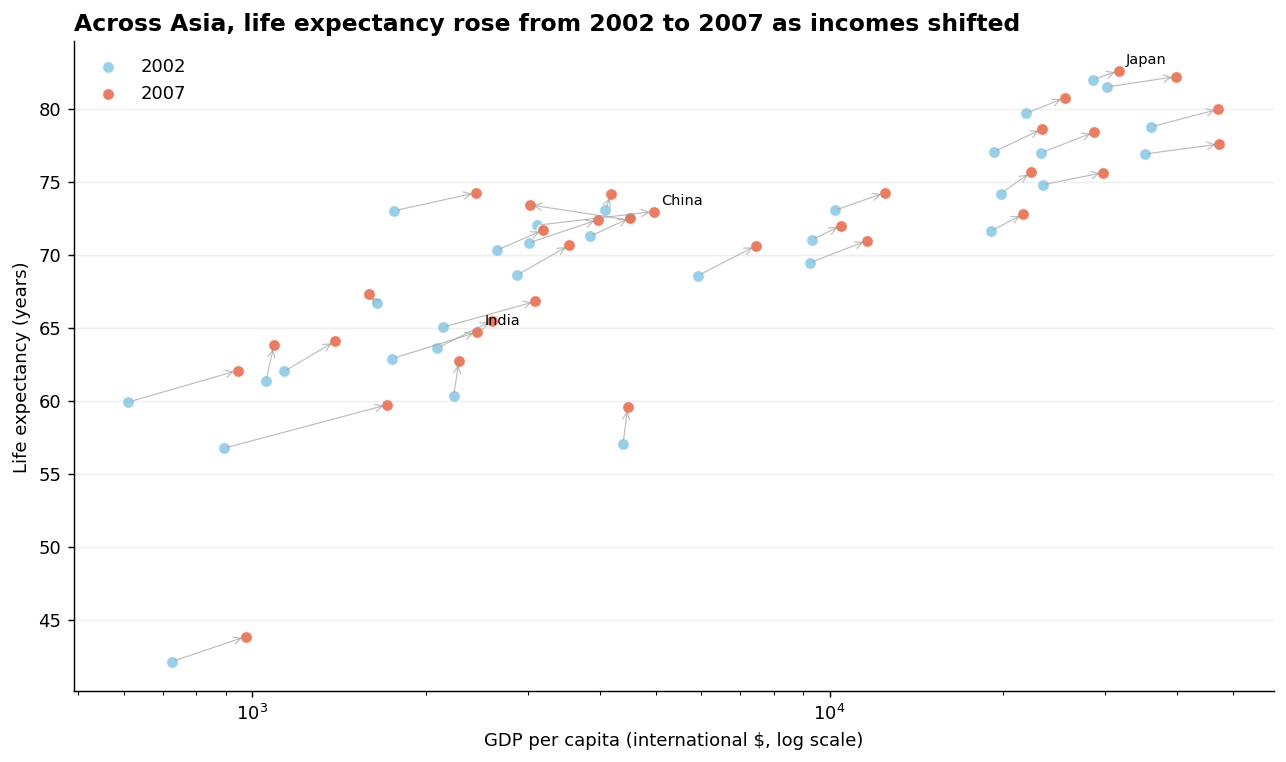

In [3]:
# Compare Asia in 2002 and 2007. Arrows show each country's movement.
continent_choice = "Asia"
plot_df = df.loc[(df["continent"] == continent_choice) & (df["year"].isin([2002, 2007]))]
year_2002 = plot_df.loc[plot_df.year == 2002].set_index("country")
year_2007 = plot_df.loc[plot_df.year == 2007].set_index("country")
countries = year_2002.index.intersection(year_2007.index)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(year_2002.loc[countries, "gdpPercap"], year_2002.loc[countries, "lifeExp"],
           s=48, color="#8ECAE6", edgecolor="white", label="2002", alpha=.9)
ax.scatter(year_2007.loc[countries, "gdpPercap"], year_2007.loc[countries, "lifeExp"],
           s=48, color="#E76F51", edgecolor="white", label="2007", alpha=.9)
for country in countries:
    ax.annotate("", xy=(year_2007.loc[country, "gdpPercap"], year_2007.loc[country, "lifeExp"]),
                xytext=(year_2002.loc[country, "gdpPercap"], year_2002.loc[country, "lifeExp"]),
                arrowprops=dict(arrowstyle="->", color="#999999", linewidth=.65, alpha=.65))
for country in ["China", "India", "Japan"]:
    if country in countries:
        ax.annotate(country, (year_2007.loc[country, "gdpPercap"], year_2007.loc[country, "lifeExp"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_title("Across Asia, life expectancy rose from 2002 to 2007 as incomes shifted",
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("GDP per capita (international $, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.grid(axis="y", alpha=.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## Task 2 — Bubble chart: one continent highlighted

**Insight:** Asian countries span a broad income range, and life expectancy also varies. Asian countries are highlighted in teal; all other continents are grey. Bubble size represents population, with `size_max` applied to keep large populations from overwhelming the chart.

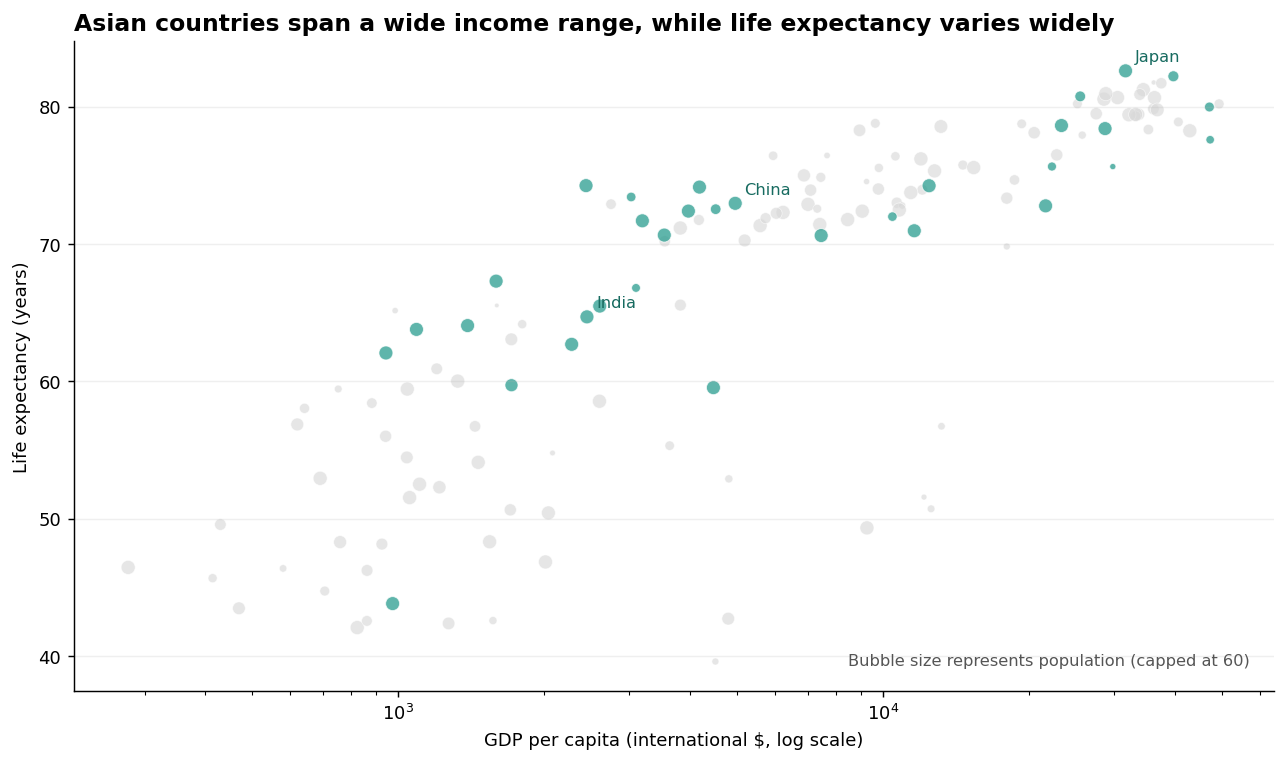

In [4]:
# Full 2007 dataset: highlight Asia and grey out all other continents.
year_choice = 2007
highlight_continent = "Asia"
bubble_df = df.loc[df["year"] == year_choice].copy()
others = bubble_df.loc[bubble_df["continent"] != highlight_continent]
highlight = bubble_df.loc[bubble_df["continent"] == highlight_continent]

# Population-to-marker sizing with a maximum marker size (size_max = 60).
def bubble_size(population, size_max=60):
    return np.minimum(np.sqrt(population / 1_000_000) * 14, size_max)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(others["gdpPercap"], others["lifeExp"], s=bubble_size(others["pop"]),
           color="#D9D9D9", alpha=.65, edgecolors="white", linewidth=.4)
ax.scatter(highlight["gdpPercap"], highlight["lifeExp"], s=bubble_size(highlight["pop"]),
           color="#2A9D8F", alpha=.75, edgecolors="white", linewidth=.5)
ax.set_xscale("log")
ax.set_title("Asian countries span a wide income range, while life expectancy varies widely",
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("GDP per capita (international $, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.grid(axis="y", alpha=.2)
ax.spines[["top", "right"]].set_visible(False)
for country in ["China", "India", "Japan"]:
    row = highlight.loc[highlight["country"] == country]
    if not row.empty:
        r = row.iloc[0]
        ax.annotate(country, (r["gdpPercap"], r["lifeExp"]), xytext=(5, 5),
                    textcoords="offset points", fontsize=9, color="#176B60")
ax.text(.98, .04, "Bubble size represents population (capped at 60)",
        transform=ax.transAxes, ha="right", fontsize=9, color="#555555")
plt.tight_layout()
plt.show()


## Key takeaway

Position compares GDP per capita with life expectancy, while bubble size adds population. Colour directs attention to Asia without using a rainbow palette. These are descriptive relationships; they do not prove that higher GDP causes longer life expectancy.